# __alpha_test — is `additive` GoalScope measuring the *magnitude* of the encoding?

**Draft only.** Nothing in `src/` or `scripts/` is touched here; the point is to look at the
proposed intervention qualitatively before deciding whether to change the pipeline and re-run the
evals.

### The current intervention, confirmed from the code

`goalscope.apply_goalscope`, additive branch (`goalscope.py:756`):

```python
sv_batch = alpha * steering_vecs[chunk_start:chunk_end]      # alpha * g_enc
PatchSpec(location=(layer_name, -1), patch=sv_batch, strategy="add", on_pass="all")
```

and `functional.py:894`: `current_state[:, token_idx, :] += patch.patch`. So

$$h_{\text{patch}} = h + \alpha \cdot g_{\text{enc}}$$

— a **fixed, precomputed** vector, added identically at *every* layer in `steer_layer_range` and at
*every* decode step. Confirmed.

### Why that is a problem, and two amplifiers

The injected magnitude is `alpha * ||g_enc||`, an absolute quantity, while the thing it perturbs
has magnitude `||h||`. Nothing holds the *ratio* fixed, so a comparison across conditions can be
reading magnitude rather than quality. Two places this bites hardest:

1. **The residual norm grows with depth.** A fixed `alpha * g_enc` is therefore a large relative
   perturbation at the bottom of the band and a small one at the top — within a single run.
2. **`||g_enc||` grows with the number of heads.** `g_enc` is a *sum* of per-head contributions, so
   a 300-head set injects more than a 25-head set at the same alpha. That is exactly the sparsity
   sweep (1b), where it would masquerade as "more heads encode more".

The same argument applies to 1a: full-residual patchscope injects something of magnitude `||h||`,
while additive GoalScope injects `alpha * ||g_enc||`. They are not magnitude-matched.

### The proposed fix

$$h_{\text{patch}} = h + \alpha \cdot \frac{g_{\text{enc}}}{\lVert g_{\text{enc}} \rVert} \cdot \lVert h \rVert$$

`alpha` now means "add this fraction of the current residual norm, along the goal direction" — the
*direction* is the encoding and the *magnitude* is controlled. Note `||h||` is layer- and
step-specific, so this **cannot be a precomputed tensor**: it has to be computed inside the hook.
That is why this is a real change to the intervention path and not a rescaling of alpha.

`replace` is untouched by any of this — it overwrites head outputs and never adds.

§1 measures the two amplifiers. §2 implements the normalized intervention. §3 puts the two
verbalizations side by side.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,7")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.panel import Panel
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.markup import escape
from src.utils import logging_utils, env_utils

logging_utils.configure(level=logging.WARNING)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)
RES = env_utils.DEFAULT_RESULTS_DIR

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER, N_HEADS = mt.n_layer, mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_heads={N_HEADS}  n_embd={mt.n_embd}")

2026-08-10 20:04:34 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

n_layer=64  n_heads=40  n_embd=5120


In [3]:
# ── goal heads, ranked by mask value (so we can take top-k) ─────────────────
GOAL_THRESHOLD, GOAL_BAND, STEER_BAND = 0.9, (25, 56), (35, 46)
gck = torch.load(os.path.join(RES, f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt"),
                 map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmv = gck["mask_values"].numpy().copy()
banded = gmv.copy(); banded[:GOAL_BAND[0]] = 0; banded[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(banded > GOAL_THRESHOLD)]

def top_heads(k):
    """Top-k by mask value inside the band (ties -> ascending index, see 16/head_inspection)."""
    flat = banded.ravel()
    order = np.argsort(-flat, kind="stable")[:k]
    return sorted([(goal_layers[int(i) // gmv.shape[1]], int(i) % gmv.shape[1]) for i in order])

print(f"goal heads @>{GOAL_THRESHOLD} band {GOAL_BAND}: {len(goal_heads)}  ·  steer band {STEER_BAND}")

# knobs used downstream (kept here so the prompt cell can be rewritten freely)
ALPHA    = 0.2      # the alpha the existing `additive` evals were run at
DATATYPE = "int"    # independent sub-task corpus

goal heads @>0.9 band (25, 56): 122  ·  steer band (35, 46)


In [28]:
# ── the source prompt: one random example from the INDEPENDENT sub-task corpus ──
# Re-run this cell to draw a different one; everything downstream follows.
from scripts.evaluation.eval_goalscope import build_corpus, build_prompt
from src.functional import generate_with_patch
from src.tokens import prepare_input


corpus = build_corpus(
    n_specs = 3,
    num_conditions = [5],
    seed = 12345,
    datatype = "int"
)

_stub = build_prompt(
    mt = mt,
    sample = corpus[0],
)


# _messages = [
#     {"role": "system", "content": "You are a helpful coding assistant."},
#     {
#         "role": "user",
#         "content": """Implement the mergesort function in Python. 
# Make sure that your code is inside <code> and </code> tags. Write only the code, no explanations, no comments or docstrings.""",
#     },
#     {"role": "assistant", "content": "<code>\n"},
# ]

# _stub = mt.tokenizer.apply_chat_template(
#     _messages,
#     add_generation_prompt=False,
#     continue_final_message=True,
#     tokenize=False,
#     chat_template_kwargs={"enable_thinking": False},
# )
_gen = generate_with_patch(
    mt=mt, inputs=_stub, max_new_tokens=256, do_sample=False, remove_prefix=True
)[0].split("</code>")[0]
PROMPT = _stub + _gen


rich_print(f"[gray]{_stub}[/gray][sea_green3]{_gen}[/sea_green3]")

rich_print(
    Panel(
        Text(PROMPT.split("<code>")[-1]),
        title="code segment GoalScope will run over",
        title_align="left",
        border_style="grey42",
        padding=(0, 1),
    )
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is positive
2. n is a triangular number
3. n is smaller than the number obtained by reversing its digits
4. n is divisible by 20
5. n is a perfect cube

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = n > 0
    b = (8 * n + 1) ** 0.5 % 1 == 0
    c = n < int(str(n)[::-1])
    d = n % 20 == 0
    e = round(n ** (1/3)) ** 3 == n
    print(f"a={a}, b={b}, c={c}, d={d}, e={e}, all={a and b and c and d and e}")

╭─ code segment GoalScope will run over ──────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ def check_conditions(n: int):                                                                                   │
│     a = n > 0                                                                                                   │
│     b = (8 * n + 1) ** 0.5 % 1 == 0                                                                             │
│     c = n < int(str(n)[::-1])                                                                                   │
│     d = n % 20 == 0                                                                                             │
│     e = round(n ** (1/3)) ** 3 == n                                                                             │
│     print(f"a={a}, b={b}, c={c}, d={d}, e={e}, all={a and b and c and d and e}")                                │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 1. The two amplifiers, measured

Before changing anything: how large is `alpha * ||g_enc||` compared with `||h||`, and how does each
side move with layer and with head count?

               relative size of the injection at alpha=0.2 (position 349)               
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ #heads         ┃ ‖g_enc‖ ┃ alpha·‖g_enc‖ ┃ vs ‖h‖ @L35 ┃ vs ‖h‖ @L45 ┃ ratio L35/L45 ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ 25             │    45.7 │           9.1 │       0.035 │       0.029 │         1.20x │
│ 50             │    75.0 │          15.0 │       0.058 │       0.048 │         1.20x │
│ 100            │   107.4 │          21.5 │       0.083 │       0.069 │         1.20x │
│ 150            │   140.3 │          28.1 │       0.108 │       0.090 │         1.20x │
│ 200            │   166.7 │          33.3 │       0.128 │       0.107 │         1.20x │
│ 300            │   178.7 │          35.7 │       0.138 │       0.115 │         1.20x │
│ selected (122) │   124.4 │          24.9 │       0.096 │       0.080 │         1.20x │
└────────────────┴─────────┴───────────────┴─────────────┴─────────────┴───────────────┘

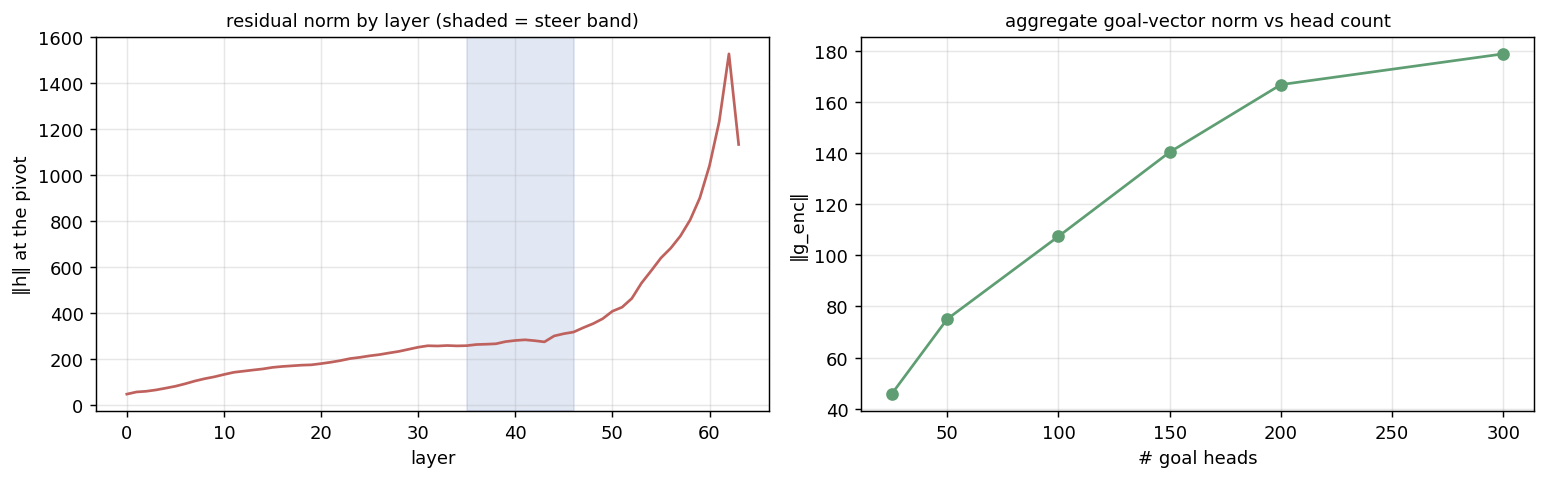

If ‖g_enc‖ climbs with head count, the sparsity sweep (1b) at fixed alpha confounds 'more heads' with 'stronger 
injection'. If ‖h‖ climbs across the steer band, the SAME run applies a different relative perturbation at each 
layer.

In [29]:
# ── §1: ||h|| by layer, and ||g_enc|| by head count ────────────────────────
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.tokens import prepare_input
from src.functional import get_hs

tok = prepare_input(prompts=PROMPT, tokenizer=mt)
POS = int(tok.input_ids.shape[1]) - 1                    # last token of the source segment

# ||h|| per layer at that position (the quantity the fix normalises against)
hs = get_hs(mt=mt, input=tok, locations=[(mt.layer_name_format.format(l), POS)
                                         for l in range(N_LAYER)])
h_norm = np.array([float(hs[(mt.layer_name_format.format(l), POS)].float().norm())
                   for l in range(N_LAYER)])

# ||g_enc|| for nested head sets
KS = [25, 50, 100, 150, 200, 300]
g_norm = {}
for k in KS:
    g = collect_head_steering_vecs(mt=mt, src_tokenized=tok, selected_heads=top_heads(k),
                                   token_positions=[POS])[0][0]
    g_norm[k] = float(g.float().norm())
g_sel = float(collect_head_steering_vecs(mt=mt, src_tokenized=tok, selected_heads=goal_heads,
                                         token_positions=[POS])[0][0].float().norm())

t = Table(title=f"relative size of the injection at alpha={ALPHA} (position {POS})")
for c in ["#heads", "‖g_enc‖", f"alpha·‖g_enc‖", "vs ‖h‖ @L35", "vs ‖h‖ @L45", "ratio L35/L45"]:
    t.add_column(c, justify="right" if c != "#heads" else "left")
for k in KS + ["selected"]:
    gn = g_sel if k == "selected" else g_norm[k]
    lo, hi = h_norm[STEER_BAND[0]], h_norm[STEER_BAND[1] - 1]
    t.add_row(str(k) + (f" ({len(goal_heads)})" if k == "selected" else ""), f"{gn:.1f}",
              f"{ALPHA * gn:.1f}", f"{ALPHA * gn / lo:.3f}", f"{ALPHA * gn / hi:.3f}",
              f"{hi / lo:.2f}x")
rich_print(t)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), dpi=130)
axes[0].plot(h_norm, color="#BF625E")
axes[0].axvspan(*STEER_BAND, color="#5E7CBF", alpha=.18)
axes[0].set_xlabel("layer"); axes[0].set_ylabel("‖h‖ at the pivot")
axes[0].set_title("residual norm by layer (shaded = steer band)", fontsize=10); axes[0].grid(alpha=.3)
axes[1].plot(KS, [g_norm[k] for k in KS], "o-", color="#5E9E72")
axes[1].set_xlabel("# goal heads"); axes[1].set_ylabel("‖g_enc‖")
axes[1].set_title("aggregate goal-vector norm vs head count", fontsize=10); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

rich_print("[grey58]If ‖g_enc‖ climbs with head count, the sparsity sweep (1b) at fixed alpha "
           "confounds 'more heads' with 'stronger injection'. If ‖h‖ climbs across the steer band, "
           "the SAME run applies a different relative perturbation at each layer.[/grey58]")

## 2. The normalized intervention

`||h||` is layer- and step-specific, so the injection cannot be a precomputed tensor — it has to be
computed inside the hook. `goalscope_normalized` below mirrors `apply_goalscope`'s additive path
exactly (same segment positions, same `collect_head_steering_vecs`, same probe prompt, same greedy
decode with the patch live at every step) and differs **only** in what gets added:

```
current      h[:, -1, :] += alpha * g_enc                       # fixed vector
normalized   h[:, -1, :] += alpha * ||h[:, -1, :]|| * ĝ_enc     # ĝ = g_enc / ||g_enc||
```

The **current** arm is not reimplemented — it calls `apply_goalscope` directly, so the baseline is
the production path rather than my reading of it.

**`alpha` changes meaning.** It is now "add this fraction of the current residual norm", applied at
each of the `steer_layer_range` layers. The old alpha=0.2 has no reason to be the right value under
the new parameterisation — §2b sweeps it.

In [30]:
# ── §2: `additive_norm` is now IN apply_goalscope; this draft stays as a cross-check ──
# The hand-rolled version below is kept only to verify the library path against an
# independent implementation (§2c). For everything else use
#     apply_goalscope(..., strategy="additive_norm", alpha=...)
import baukit
from src.goals.goalscope import apply_goalscope, _build_goalscope_prompt

@torch.no_grad()
def goalscope_normalized(prompt, mt, selected_heads, token_positions, steer_layer_range,
                         alpha=0.2, max_new_tokens=64, batch_size=16):
    """apply_goalscope(strategy='additive') with the injection scaled to ||h||.

    Identical scaffolding — same steering vectors, same probe, patch live at every decode step —
    so any difference in the read-out is attributable to the normalisation alone."""
    src_tok = prepare_input(prompts=prompt, tokenizer=mt)
    G = collect_head_steering_vecs(mt=mt, src_tokenized=src_tok, selected_heads=selected_heads,
                                   token_positions=list(token_positions))[0]      # (n_seg, n_embd)
    Gu = (G.float() / G.float().norm(dim=-1, keepdim=True).clamp_min(1e-6))       # unit directions
    dest = prepare_input(prompts=_build_goalscope_prompt(mt), tokenizer=mt)
    src_ids = src_tok.input_ids[0].tolist()          # for the `token` field show_patchscope needs
    names = [mt.layer_name_format.format(l) for l in range(*steer_layer_range)]
    eos = mt.tokenizer.eos_token_id
    out = []
    for s in tqdm(range(0, len(token_positions), batch_size), desc=f"normalized[a={alpha}]"):
        g = Gu[s:s + batch_size]
        B = g.shape[0]
        ids = dest.input_ids.expand(B, -1).clone()
        att = dest.attention_mask.expand(B, -1).clone()

        def edit(output, layer):
            is_t = isinstance(output, tuple)
            hs = output[0] if is_t else output
            h = hs[:, -1, :]
            n = h.float().norm(dim=-1, keepdim=True)          # per-item, per-layer, per-step
            hs[:, -1, :] = h + (alpha * n * g.to(h.device)).to(h.dtype)
            return (hs,) + output[1:] if is_t else hs

        past, cur, done = None, ids, torch.zeros(B, dtype=torch.bool)
        toks = []
        for _ in range(max_new_tokens):
            with baukit.TraceDict(mt._model, names, edit_output=edit):
                o = mt._model(input_ids=cur, attention_mask=att, past_key_values=past,
                              use_cache=True)
            past = o.past_key_values
            nxt = o.logits[:, -1, :].argmax(-1)
            nxt = torch.where(done.to(nxt.device), torch.full_like(nxt, eos), nxt)
            toks.append(nxt)
            done |= (nxt == eos).cpu()
            if bool(done.all()):
                break
            cur = nxt.unsqueeze(1)
            att = torch.cat([att, torch.ones_like(cur)], dim=1)
        T = torch.stack(toks, dim=1)
        for b in range(B):
            p = int(token_positions[s + b])
            out.append(dict(pos=p, token=mt.tokenizer.decode([src_ids[p]]), scoped=True,
                            patched_gen=mt.tokenizer.decode(T[b], skip_special_tokens=True).strip()))
    return out

## 3. Side by side

Same prompt, same head set, same steer band, same positions — one table per token position, current
intervention against normalized. Read the verbalizations, not the rates.

In [36]:
# ── §3: current vs normalized, per token position ──────────────────────────
ALPHA_CURRENT = 0.2
ALPHA_NORM = 0.1

GS_KW = dict(mt=mt, selected_heads=goal_heads, steer_layer_range=STEER_BAND,
             max_new_tokens=48, batch_size=16)
ids_all = prepare_input(prompts=PROMPT, tokenizer=mt).input_ids[0].tolist()
code_start = len(mt.tokenizer(PROMPT.split("<code>")[0] + "<code>",
                              add_special_tokens=False)["input_ids"])
POSITIONS = list(range(code_start, len(ids_all)))[-54: -20]      # the tail of the code segment

cur = apply_goalscope(prompt=PROMPT, strategy="additive", alpha=ALPHA_CURRENT, show=False,
                      n_steer_tokens="all", include_noncode=True,
                      token_positions=POSITIONS, **GS_KW)
nrm = goalscope_normalized(PROMPT, mt, goal_heads, POSITIONS, STEER_BAND,
                           alpha=ALPHA_NORM, max_new_tokens=48, batch_size=16)
cur_by = {r["pos"]: (r.get("patched_gen") or "").strip() for r in cur}
nrm_by = {r["pos"]: r["patched_gen"] for r in nrm}

t = Table(title=f"GoalScope read-out · alpha={ALPHA_CURRENT} vs {ALPHA_NORM} · heads={len(goal_heads)} · band {STEER_BAND}",
          box=SIMPLE_HEAVY, expand=True, pad_edge=False, title_justify="left")
t.add_column("pos", justify="right", no_wrap=True)
t.add_column("token", no_wrap=True)
t.add_column(f"current   h + a*g", style="sea_green3", ratio=1, overflow="fold")
t.add_column(f"normalized   h + a*||h||*g_hat", style="salmon1", ratio=1, overflow="fold")
for p in POSITIONS:
    t.add_row(str(p), repr(mt.tokenizer.decode([ids_all[p]])),
              escape(cur_by.get(p, "")), escape(nrm_by.get(p, "")))
rich_print(t)

GoalScope[additive]:   0%|          | 0/3 [00:00<?, ?it/s]

normalized[a=0.1]:   0%|          | 0/3 [00:00<?, ?it/s]

GoalScope read-out · alpha=0.2 vs 0.1 · heads=122 · band (35, 46)                                                  
                                                                                                                   
 pos   token      current   h + a*g                                normalized   h + a*||h||*g_hat                  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 296   '0'        I'm checking if the variable is divisible by     I'm checking if the current value is divisible  
                  1.                                               by 1000.                                        
 297   '\n'       I'm checking if the current value is equal to    I'm checking if the current value is equal to   
                  its cube root, which also confirms it's a        its cube root, which is equivalent to checking  
                  perfect sixth power.                             if it's a perfect cube.                         
 298   '   '      I'm evaluating `expression` and printing the     I'm evaluating the condition and updating the   
                  result of `expression == True`, where            variable, then printing the result.             
                  `expression` is `(a == b) and (b == c) and (c                                                    
                  == d)`.                                                                                          
 299   ' e'       Sure, please provide the line of code you want   I'm checking if the variable is equal to a      
                  me to evaluate.                                  specific value.                                 
 300   ' ='       I'm checking if a number is a perfect cube by    I'm checking if a variable is a perfect cube.   
                  verifying if its cube root is an integer.                                                        
 301   ' round'   I'm calculating the cube root of an integer by   I'm calculating the cube root of a number.      
                  raising it to the power of 1/3 and checking if                                                   
                  the result is an integer.                                                                        
 302   '(n'       I'm calculating the cube root of a number to     I'm calculating the cube root of a number.      
                  check if it's a perfect cube.                                                                    
 303   ' **'      I'm calculating the cube root of a number to     I'm calculating the cube root of a number by    
                  check if it's a perfect cube.                    raising it to the power of 1/3.                 
 304   ' ('       I'm calculating the cube root of the number by   I'm calculating the cube root of a number by    
                  raising it to the power of 1/3.                  raising it to the power of 1/3.                 
 305   '1'        I'm calculating the cube root by raising the     I'm calculating the cube root of a number by    
                  number to the power of 1/3.                      raising it to the power of 1/3.                 
 306   '/'        I'm calculating the cube root by raising the     I'm calculating the cube root of a number by    
                  number to the power of 1/3.                      raising it to the power of 1/3.                 
 307   '3'        I'm calculating the cube root of an integer      I'm calculating the cube root of a number and   
                  and checking if it's an exact cube.              checking if it's an integer.                    
 308   '))'       I'm calculating the cube root of an integer by   I'm calculating the cube root of a number.      
                  raising it to the power of 1/3 and then cubing                                                   
                  it to check if it's a perfect cube.   

In [ ]:
# ── §2c: does the library path match the independent draft? ────────────────
# apply_goalscope(strategy="additive_norm") normalises g_enc up front and lets `add_norm` supply
# ||h|| at each patch site; goalscope_normalized does the whole thing in one hook. Same numbers
# => the library wiring is right.
_pos = POSITIONS[-4:]
_lib = {r["pos"]: (r.get("patched_gen") or "").strip() for r in
        apply_goalscope(prompt=PROMPT, strategy="additive_norm", alpha=ALPHA, show=False,
                        n_steer_tokens="all", include_noncode=True,
                        token_positions=_pos, **{**GS_KW, "max_new_tokens": 40})}
_ref = {r["pos"]: r["patched_gen"] for r in
        goalscope_normalized(PROMPT, mt, goal_heads, _pos, STEER_BAND,
                             alpha=ALPHA, max_new_tokens=40, batch_size=8)}
t = Table(title="library `additive_norm` vs the hand-rolled draft", box=SIMPLE_HEAVY,
          expand=True, pad_edge=False, title_justify="left")
t.add_column("pos", justify="right"); t.add_column("match", justify="center")
t.add_column("apply_goalscope", ratio=1, overflow="fold")
t.add_column("draft", ratio=1, overflow="fold")
for p in _pos:
    same = _lib.get(p, "") == _ref.get(p, "")
    t.add_row(str(p), Text("=" if same else "DIFF", style="green" if same else "red"),
              escape(_lib.get(p, "")), escape(_ref.get(p, "")))
rich_print(t)

## 2b. What is the right alpha now?

`alpha` no longer has its old units, so the value carried over from the additive runs (0.2) is not
meaningful under the new parameterisation. A few positions across a sweep — looking for the range
where the read-out is on-topic without collapsing into degenerate text.

In [37]:
print(PROMPT)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is positive
2. n is a triangular number
3. n is smaller than the number obtained by reversing its digits
4. n is divisible by 20
5. n is a perfect cube

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local var

In [39]:
# ── §2b: alpha sweep for the normalized intervention ───────────────────────
SWEEP = [0.05, 0.1, 0.15, 0.2]
SWEEP_POS = POSITIONS[-64: -20]
runs = {a: {r["pos"]: (r.get("patched_gen") or "").strip() for r in
            apply_goalscope(prompt=PROMPT, strategy="additive_norm", alpha=a, show=False,
                            n_steer_tokens="all", include_noncode=True,
                            token_positions=SWEEP_POS, **{**GS_KW, "max_new_tokens": 40})}
        for a in SWEEP}
base = {r["pos"]: (r.get("patched_gen") or "").strip() for r in
        apply_goalscope(prompt=PROMPT, strategy="additive", alpha=ALPHA, show=False,
                        n_steer_tokens="all", include_noncode=True,
                        token_positions=SWEEP_POS, **{**GS_KW, "max_new_tokens": 40})}
for p in SWEEP_POS:
    t = Table(title=f"pos {p}  ·  token {mt.tokenizer.decode([ids_all[p]])!r}",
              box=SIMPLE_HEAVY, expand=True, pad_edge=False, title_justify="left")
    t.add_column("alpha", justify="right", no_wrap=True)
    t.add_column("read-out", overflow="fold", ratio=1)
    t.add_row(Text(f"{ALPHA} (current)", style="bold"), Text(base.get(p, ""), style="sea_green3"))
    for a in SWEEP:
        t.add_row(f"{a:g}", Text(runs[a].get(p, ""), style="salmon1"))
    rich_print(t); rich_print("")

normalized[a=0.05]:   0%|          | 0/2 [00:00<?, ?it/s]

normalized[a=0.1]:   0%|          | 0/2 [00:00<?, ?it/s]

normalized[a=0.15]:   0%|          | 0/2 [00:00<?, ?it/s]

normalized[a=0.2]:   0%|          | 0/2 [00:00<?, ?it/s]

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

pos 296  ·  token '0'                                                                                              
                                                                                                                   
         alpha   read-out                                                                                          
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 0.2 (current)   I'm checking if the variable is divisible by 1.                                                   
          0.05   I'm analyzing the specified line of code to determine its function.                               
           0.1   I'm checking if the current value is divisible by 1000.                                           
          0.15   I'm checking if the number is a perfect cube.                                                     
           0.2   I'm not.                                                                                         

... (9 outputs left out)

pos 306  ·  token '/'                                                                                              
                                                                                                                   
         alpha   read-out                                                                                          
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 0.2 (current)   Calculating the cube root by raising the number to the power of 1/3.                              
          0.05   I'm analyzing the specific line of code to determine its function.                                
           0.1   I'm calculating the cube root of a number by raising it to the power of 1/3.                      
          0.15   Calculating the cube root of a number by raising it to the power of 1/3.                          
           0.2   I'm calculating for a perfect cube, by finding the cube root of a number.                        

pos 307  ·  token '3'                                                                                              
                                                                                                                   
         alpha   read-out                                                                                          
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 0.2 (current)   I'm calculating the cube root of an integer and checking if it's an exact cube.                   
          0.05   I'm analyzing the specific line of code to determine its function.                                
           0.1   I'm calculating the cube root of a number and checking if it's an integer.                        
          0.15   I'm calculating the cube root of a number and checking if it is an integer by cubing the rounded  
                 cube root to see if it equals the original number.                                                
           0.2   I'm take a number **round** to the nearest cube)** is a whole number)** is an whole number)** is  
                 an **perfect)** is an whole)** is an whole)** is an whole)**                                     

pos 308  ·  token '))'                                                                                             
                                                                                                                   
         alpha   read-out                                                                                          
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 0.2 (current)   I'm calculating the cube root of an integer to check if it's a perfect cube.                      
          0.05   I'm analyzing the specified line of code to determine its function.                               
           0.1   I'm calculating the cube root of a number.                                                        
          0.15   I'm calculating the cube root of an integer by cubing the rounded value of its cube root to check 
                 if it's a perfect cube.                                                                           
           0.2   I am a perfect cube, when cub = round **3 ** = x ** = x ** = x ** = x ** = x ** = x ** = x ** = x 
                 ** = x **                                                                                        

pos 309  ·  token ' **'                                                                                            
                                                                                                                   
         alpha   read-out                                                                                          
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 0.2 (current)   I'm calculating the cube root of a number by cubing it to check if it's an exact cube.            
          0.05   I'm analyzing the specified line of code to determine its function.                               
           0.1   I'm calculating the cube root of a number.                                                        
          0.15   I'm calculating the cube of an integer.                                                           
           0.2   I'm sure you know, that this is a perfect cube, {3 ** 3 ** 3} = 3.                               

## 4. Whole code segment, interactive

Both interventions over the **entire** code segment, rendered with `show_patchscope` — hover a token
for its verbalization.

* **current** — `h + alpha·g_enc` at `alpha=0.2`, the value the existing additive evals use
* **normalized** — `h + alpha·‖h‖·ĝ` at `alpha=0.1`

The positions are taken from the current arm's own scoped rows and fed to the normalized arm, so
both renders cover exactly the same tokens; the non-code rows are reused verbatim, so the two
layouts are identical and only the tooltips differ.

In [24]:
# ── the source prompt: one random example from the INDEPENDENT sub-task corpus ──
# Re-run this cell to draw a different one; everything downstream follows.
from scripts.evaluation.eval_goalscope import build_corpus, build_prompt
from src.functional import generate_with_patch
from src.tokens import prepare_input


corpus = build_corpus(
    n_specs = 3,
    num_conditions = [5],
    seed = 12345,
    datatype = DATATYPE
)

_stub = build_prompt(
    mt = mt,
    sample = corpus[0],
)


# _messages = [
#     {"role": "system", "content": "You are a helpful coding assistant."},
#     {
#         "role": "user",
#         "content": """Implement the mergesort function in Python. 
# Make sure that your code is inside <code> and </code> tags. Write only the code, no explanations, no comments or docstrings.""",
#     },
#     {"role": "assistant", "content": "<code>\n"},
# ]

# _stub = mt.tokenizer.apply_chat_template(
#     _messages,
#     add_generation_prompt=False,
#     continue_final_message=True,
#     tokenize=False,
#     chat_template_kwargs={"enable_thinking": False},
# )
_gen = generate_with_patch(
    mt=mt, inputs=_stub, max_new_tokens=256, do_sample=False, remove_prefix=True
)[0].split("</code>")[0]
PROMPT = _stub + _gen


rich_print(f"[gray]{_stub}[/gray][sea_green3]{_gen}[/sea_green3]")

rich_print(
    Panel(
        Text(PROMPT.split("<code>")[-1]),
        title="code segment GoalScope will run over",
        title_align="left",
        border_style="grey42",
        padding=(0, 1),
    )
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is positive
2. n is a triangular number
3. n is smaller than the number obtained by reversing its digits
4. n is divisible by 20
5. n is a perfect cube

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = n > 0
    b = (8 * n + 1) ** 0.5 % 1 == 0
    c = n < int(str(n)[::-1])
    d = n % 20 == 0
    e = round(n ** (1/3)) ** 3 == n
    print(f"a={a}, b={b}, c={c}, d={d}, e={e}, all={a and b and c and d and e}")

╭─ code segment GoalScope will run over ──────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ def check_conditions(n: int):                                                                                   │
│     a = n > 0                                                                                                   │
│     b = (8 * n + 1) ** 0.5 % 1 == 0                                                                             │
│     c = n < int(str(n)[::-1])                                                                                   │
│     d = n % 20 == 0                                                                                             │
│     e = round(n ** (1/3)) ** 3 == n                                                                             │
│     print(f"a={a}, b={b}, c={c}, d={d}, e={e}, all={a and b and c and d and e}")                                │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [25]:
# ── §4: whole-segment GoalScope, current vs normalized ─────────────────────
from src.goals.goalscope import show_patchscope

ALPHA_CUR, ALPHA_NRM = 0.2, 0.1

cur_full = apply_goalscope(prompt=PROMPT, mt=mt, selected_heads=goal_heads,
                           strategy="additive", alpha=ALPHA_CUR,
                           steer_layer_range=STEER_BAND, batch_size=16, max_new_tokens=64,
                           n_steer_tokens="all", include_noncode=True, show=False)
SEG_POS = [r["pos"] for r in cur_full if r.get("scoped", True)]
print(f"code segment: {len(SEG_POS)} scoped positions (of {len(cur_full)} rendered)")

nrm_full = apply_goalscope(prompt=PROMPT, mt=mt, selected_heads=goal_heads,
                           strategy="additive_norm", alpha=ALPHA_NRM,
                           steer_layer_range=STEER_BAND, batch_size=16, max_new_tokens=64,
                           n_steer_tokens="all", include_noncode=True, show=False)

show_patchscope(cur_full, title=f"CURRENT   h + a*g_enc   (alpha={ALPHA_CUR})")
show_patchscope(nrm_full, title=f"NORMALIZED   h + a*||h||*g_hat   (alpha={ALPHA_NRM})")

GoalScope[additive]:   0%|          | 0/8 [00:00<?, ?it/s]

code segment: 118 scoped positions (of 350 rendered)


normalized[a=0.1]:   0%|          | 0/8 [00:00<?, ?it/s]